# Flux post-processing chain: both gas analysers merged (2004-2026.09)

**notebook version**: `1` (29 Oct 2026)

## ℹ️ About this notebook

Joins the merged flux results of the two gas analysers into one record, 2004 to September 2026:

| Period | Source | Analyser |
|---|---|---|
| 1 January 2004 - 31 December 2015 | `IRGA75/99_FPPC_IRGA75_MERGED_2004-2017` | open-path LI-7500, CO2 flux corrected with opco |
| 1 January 2016 - 30 September 2026 | `IRGA72/99_FPPC_IRGA72_MERGED_2016-2026.09` | enclosed-path LI-7200 |

Both files carry the same column names, so every column holds one analyser per period. The column
`FLAG_FLUX_SOURCE` records it for each half-hour: 75 for the LI-7500, 72 for the LI-7200. In the
overlap 2016-2017 the LI-7200 is used. The LI-7500 stand-in run of 17 January to 20 March 2019 is
not used; that period comes from the LI-7200 chain, gap-filled.

Values are copied unchanged. Columns that only one analyser has (the manual removal flags of the
LI-7200) are empty in the other period. Known limitations of the LI-7500 years are on the site
documentation (Issues).

## ⚙️ Settings

In [1]:
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
STAGEDIR = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN"
FILES = {
    'IRGA75': rf"{STAGEDIR}\IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet",
    'IRGA72': rf"{STAGEDIR}\IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet",
}
# First half-hour of each analyser in the merged record (TIMESTAMP_MIDDLE).
PERIODS = {'IRGA75': ('2004-01-01 00:15', '2015-12-31 23:45'),
           'IRGA72': ('2016-01-01 00:15', '2026-09-30 23:45')}
SOURCE_CODES = {'IRGA75': 75, 'IRGA72': 72}
SOURCE_COL = 'FLAG_FLUX_SOURCE'

OUTNAME = "99_FPPC_MERGED_2004-2026.09"  # same name as this notebook
OUTPATH = STAGEDIR

UMOL_TO_GC = 12.011 * 1e-6 * 1800  # NEE, umol m-2 s-1 -> gC m-2 per half-hour
WM2_TO_MJ = 1800 * 1e-6  # LE and H, W m-2 -> MJ m-2 per half-hour

In [2]:
from datetime import datetime
import importlib.metadata
import textwrap

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.plotting.styles import chainplots as cp


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-31 17:25:11
diive version: v0.93.0


## 📂 Load data

In [3]:
frames = {k: dv.load_parquet(filepath=v) for k, v in FILES.items()}
for name, frame in frames.items():
    _start, _end = (pd.Timestamp(t) for t in PERIODS[name])
    assert frame.index[0] <= _start and frame.index[-1] >= _end, f"{name} does not cover {PERIODS[name]}"
    assert not frame.index.duplicated().any(), f"{name} has duplicate timestamps"
    print(f"{name}: {frame.shape[0]:,} records x {frame.shape[1]} columns, {frame.index[0]} -> {frame.index[-1]}")
_a, _b = (set(frames[k].columns) for k in FILES)
print(f"columns only in IRGA75: {sorted(_a - _b)}")
print(f"columns only in IRGA72: {sorted(_b - _a)}")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet (0.136 seconds).

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet (0.531 seconds).

IRGA75: 245,472 records x 204 columns, 2004-01-01 00:15:00 -> 2017-12-31 23:45:00
IRGA72: 188,448 records x 203 columns, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
columns only in IRGA75: ['FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHTS_TEST']
columns only in IRGA72: []


## 🔗 Merge

In [4]:
index = pd.date_range(PERIODS['IRGA75'][0], PERIODS['IRGA72'][1], freq='30min', name='TIMESTAMP_MIDDLE')
columns = list(frames['IRGA72'].columns) + [c for c in frames['IRGA75'].columns if c not in frames['IRGA72'].columns]
parts, source = [], pd.Series(np.nan, index=index, name=SOURCE_COL)
for name, (start, end) in PERIODS.items():
    _part = frames[name].loc[start:end].reindex(columns=columns)
    parts.append(_part)
    source.loc[start:end] = SOURCE_CODES[name]
merged = pd.concat(parts).reindex(index)
merged[SOURCE_COL] = source.astype('int64')
print(f"Merged: {merged.shape[0]:,} records x {merged.shape[1]} columns, {merged.index[0]} -> {merged.index[-1]}")

Merged: 398,832 records x 205 columns, 2004-01-01 00:15:00 -> 2026-09-30 23:45:00


## 🔍 Checks

In [5]:
assert merged.index.equals(index) and not merged.index.duplicated().any()
assert merged[SOURCE_COL].notna().all()
# Every value comes unchanged from the analyser of its period.
for name, (start, end) in PERIODS.items():
    _src = frames[name].loc[start:end]
    for c in _src.columns:
        assert merged.loc[start:end, c].equals(_src[c].reindex(merged.loc[start:end].index)), f"{c} changed ({name})"
# The main gap-filled series are complete over the whole record.
MAIN = ['NEE_L3.1_L3.3_CUT_50_QCF_gfXG', 'LE_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'ET_L3.1_L3.3_CUT_NONE_QCF_gfXG',
        'H_L3.1_L3.3_CUT_NONE_QCF_gfXG']
for c in MAIN:
    assert merged[c].notna().all(), f"{c} has gaps"
print("Index, sources and values verified; main gap-filled series complete:", ", ".join(MAIN))

Index, sources and values verified; main gap-filled series complete: NEE_L3.1_L3.3_CUT_50_QCF_gfXG, LE_L3.1_L3.3_CUT_NONE_QCF_gfXG, ET_L3.1_L3.3_CUT_NONE_QCF_gfXG, H_L3.1_L3.3_CUT_NONE_QCF_gfXG


### 📋 Table: half-hours per analyser and year

In [6]:
display(merged[SOURCE_COL].groupby(merged.index.year).value_counts().unstack(fill_value=0)
        .rename(columns={v: k for k, v in SOURCE_CODES.items()}))

FLAG_FLUX_SOURCE,IRGA75,IRGA72
TIMESTAMP_MIDDLE,,
2004,17568,0
2005,17520,0
2006,17520,0
2007,17520,0
2008,17568,0
2009,17520,0
2010,17520,0
2011,17520,0
2012,17568,0


### 📋 Table: annual sums of the gap-filled fluxes

`NEE` uses the CUT_50 scenario; `LE`, `ET` and `H` are not USTAR-filtered (`CUT_NONE`). 2026 ends on 30 September.

In [7]:
_vars = {'NEE (gC m-2)': ('NEE_L3.1_L3.3_CUT_50_QCF_gf{m}', UMOL_TO_GC),
         'LE (MJ m-2)': ('LE_L3.1_L3.3_CUT_NONE_QCF_gf{m}', WM2_TO_MJ),
         'ET (mm)': ('ET_L3.1_L3.3_CUT_NONE_QCF_gf{m}', 1),
         'H (MJ m-2)': ('H_L3.1_L3.3_CUT_NONE_QCF_gf{m}', WM2_TO_MJ)}
_year = merged.index.year
ANNUAL = pd.DataFrame({(_v, _mn): (merged[_p.format(m=_m)] * _g).groupby(_year).sum()
                       for _v, (_p, _g) in _vars.items() for _mn, _m in (('XGBoost', 'XG'), ('MDS', 'MDS'))})
ANNUAL.insert(0, 'analyser', merged[SOURCE_COL].groupby(_year).first().map({v: k for k, v in SOURCE_CODES.items()}))
ANNUAL.index.name = 'year'
display(ANNUAL.round(0))

analyser NEE (gC m-2)        LE (MJ m-2)         ET (mm)         \
                   XGBoost    MDS     XGBoost     MDS XGBoost    MDS   
year                                                                   
2004   IRGA75         40.0   -8.0      1846.0  1926.0   748.0  780.0   
2005   IRGA75         62.0   28.0      1718.0  1770.0   697.0  718.0   
2006   IRGA75         43.0  169.0      1549.0  1447.0   629.0  587.0   
2007   IRGA75       -180.0 -119.0      1693.0  1647.0   687.0  668.0   
2008   IRGA75        -57.0   39.0      2061.0  1965.0   836.0  797.0   
2009   IRGA75        -57.0   11.0      2160.0  2096.0   877.0  851.0   
2010   IRGA75       -168.0  -67.0      2266.0  2200.0   919.0  892.0   
2011   IRGA75       -312.0 -282.0      1791.0  1747.0   727.0  709.0   
2012   IRGA75       -338.0 -367.0      1903.0  1870.0   772.0  759.0   
2013   IRGA75       -297.0 -111.0      1721.0  1701.0   698.0  690.0   
2014   IRGA75       -305.0 -172.0      1714.0  1672.0   695.0  678.0   
2015   IRGA75       -255.0 -217.0      1697.0  1645.0   689.0  668.0   
2016   IRGA72       -125.0 -290.0      1520.0  1635.0   618.0  664.0   
2017   IRGA72         71.0   13.0      1516.0  1517.0   617.0  617.0   
2018   IRGA72       -114.0 -209.0      1408.0  1414.0   573.0  575.0   
2019   IRGA72       -290.0 -323.0      1465.0  1435.0   596.0  584.0   
2020   IRGA72       -267.0 -331.0      1484.0  1467.0   603.0  596.0   
2021   IRGA72       -121.0 -118.0      1457.0  1429.0   591.0  580.0   
2022   IRGA72        -13.0  -77.0      1531.0  1520.0   622.0  618.0   
2023   IRGA72          5.0  -23.0      1599.0  1591.0   650.0  647.0   
2024   IRGA72        -45.0  -52.0      1551.0  1545.0   630.0  628.0   
2025   IRGA72       -340.0 -441.0      1610.0  1598.0   654.0  650.0   
2026   IRGA72       -291.0 -344.0      1415.0  1391.0   576.0  567.0   

     H (MJ m-2)          
        XGBoost     MDS  
year                     
2004     1106.0  1634.0  
2005      994.0  1013.0  
2006      927.0   919.0  
2007     1013.0  1014.0  
2008      936.0   937.0  
2009      958.0   958.0  
2010      915.0   916.0  
2011     1201.0  1208.0  
2012     1033.0  1013.0  
2013     1171.0  1163.0  
2014     1144.0  1143.0  
2015     1458.0  1439.0  
2016     1116.0  1070.0  
2017     1302.0  1295.0  
2018     1298.0  1283.0  
2019     1172.0  1153.0  
2020     1381.0  1380.0  
2021     1209.0  1221.0  
2022     1432.0  1443.0  
2023     1022.0  1016.0  
2024      792.0   800.0  
2025     1053.0  1067.0  
2026     1366.0  1365.0

### 📊 Plot: cumulative NEE over the merged record

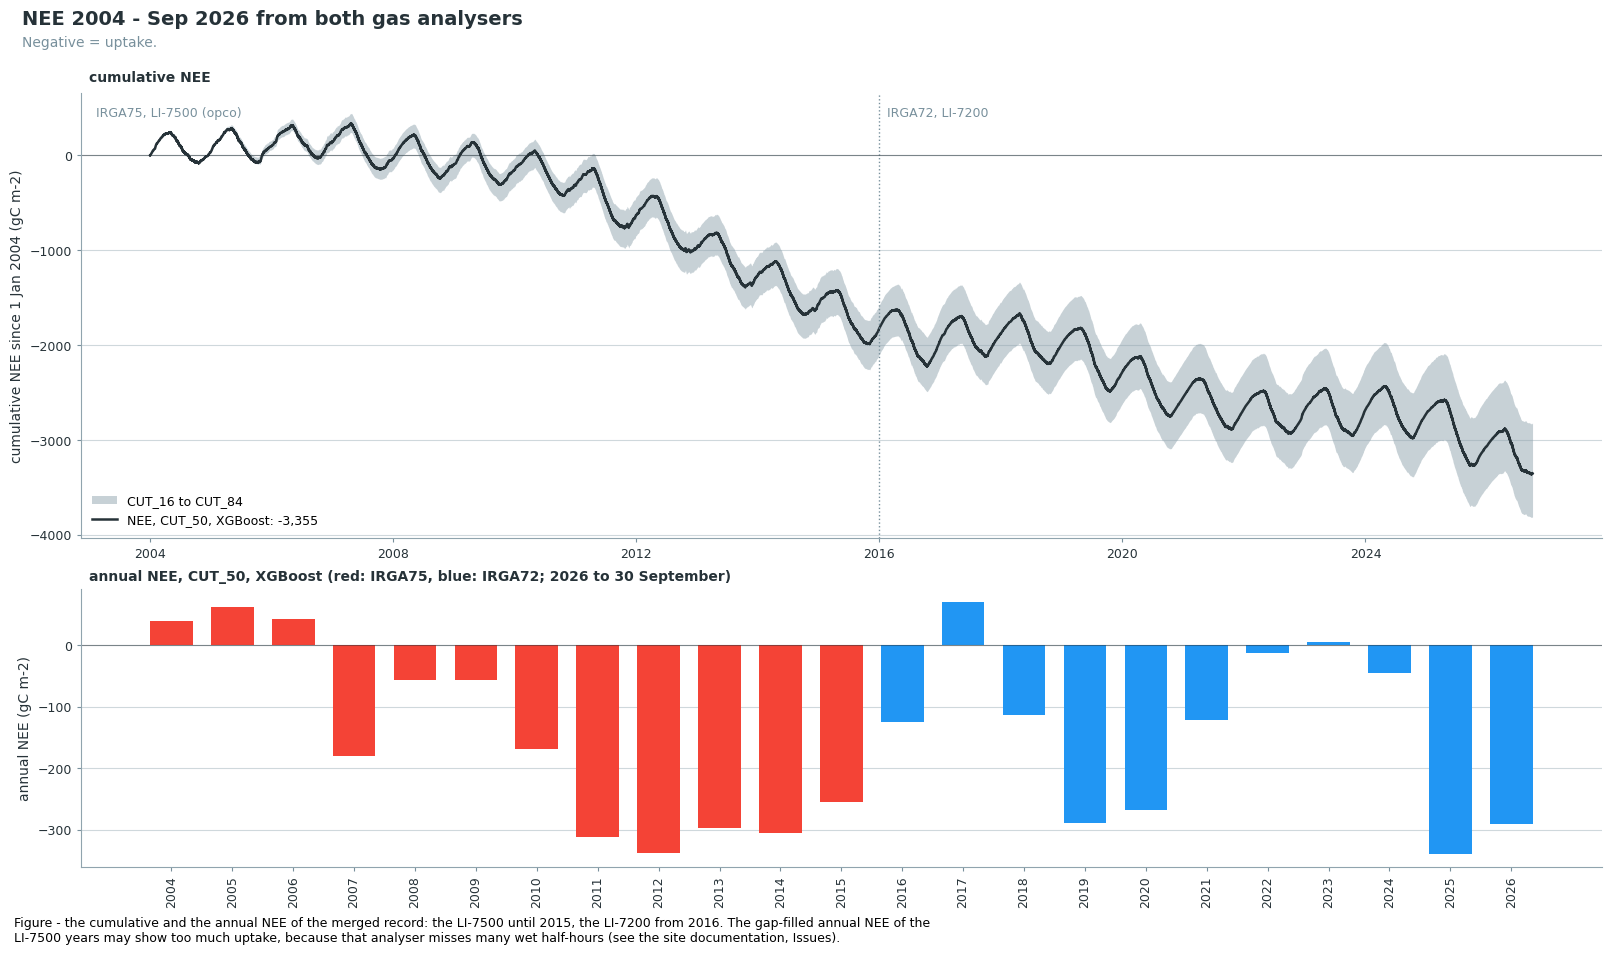

In [8]:
_cols = {s: f'NEE_L3.1_L3.3_{s}_QCF_gfXG' for s in ('CUT_16', 'CUT_50', 'CUT_84')}
_cum = {s: (merged[c] * UMOL_TO_GC).cumsum() for s, c in _cols.items()}
_switch = pd.Timestamp(PERIODS['IRGA72'][0])
fig, axs = plt.subplots(2, 1, figsize=(16, 9.5), layout='constrained', height_ratios=[1.6, 1])
ax = axs[0]
ax.fill_between(_cum['CUT_50'].index, np.minimum(_cum['CUT_16'], _cum['CUT_84']),
                np.maximum(_cum['CUT_16'], _cum['CUT_84']), color=cp.KEPT, alpha=0.5, linewidth=0,
                label='CUT_16 to CUT_84')
ax.plot(_cum['CUT_50'].index, _cum['CUT_50'].to_numpy(), color=cp.INK, linewidth=1.8,
        label=f"NEE, CUT_50, XGBoost: {_cum['CUT_50'].iloc[-1]:,.0f}")
ax.axvline(_switch, color=cp.MUTED, linewidth=1, linestyle=':')
ax.text(0.01, 0.97, 'IRGA75, LI-7500 (opco)', transform=ax.transAxes, va='top', fontsize=9, color=cp.MUTED)
ax.text(_switch, 0.97, '  IRGA72, LI-7200', transform=ax.get_xaxis_transform(), va='top', fontsize=9, color=cp.MUTED)
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_ylabel('cumulative NEE since 1 Jan 2004 (gC m-2)')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=9, loc='lower left')
cp.panel_label(ax, 'cumulative NEE')
ax = axs[1]
_ann = ANNUAL[('NEE (gC m-2)', 'XGBoost')]
_x = _ann.index.to_numpy()
ax.bar(_x, _ann.to_numpy(), width=0.7, color=np.where(_x < _switch.year, cp.REJECTED, cp.CLEANED))
ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
ax.set_xticks(_x, [str(v) for v in _x], rotation=90)
ax.set_ylabel('annual NEE (gC m-2)')
cp.style_axes(ax)
cp.panel_label(ax, 'annual NEE, CUT_50, XGBoost (red: IRGA75, blue: IRGA72; 2026 to 30 September)')
cp.figure_title(fig, 'NEE 2004 - Sep 2026 from both gas analysers', 'Negative = uptake.')
figcap(fig, "the cumulative and the annual NEE of the merged record: the LI-7500 until 2015, the LI-7200 from "
            "2016. The gap-filled annual NEE of the LI-7500 years may show too much uptake, because that "
            "analyser misses many wet half-hours (see the site documentation, Issues).")
plt.show()

### 📊 Plot: daily time series of the main fluxes, 2004 - Sep 2026

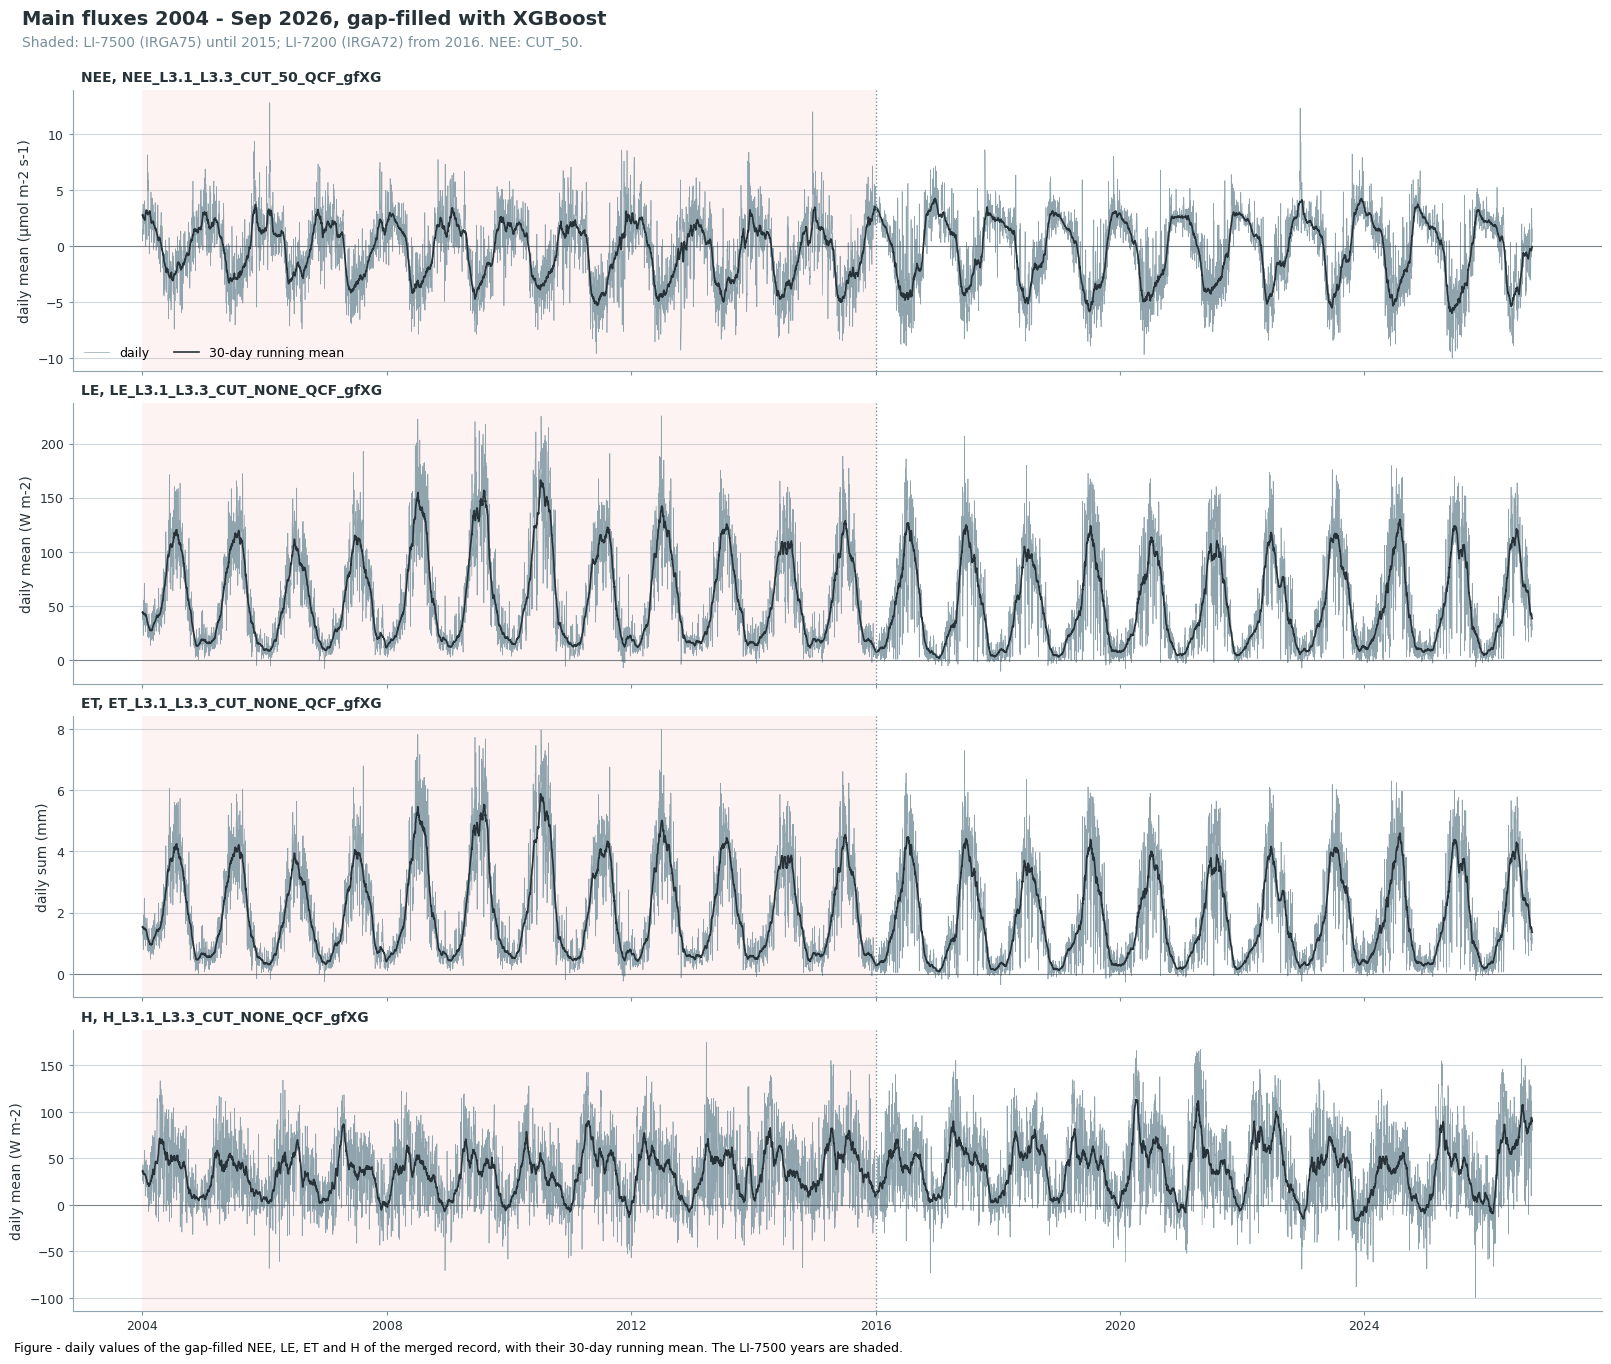

In [9]:
# Daily values of the gap-filled series (XGBoost), with a 30-day running mean. The shading marks
# the LI-7500 period.
SERIES = {'NEE': ('NEE_L3.1_L3.3_CUT_50_QCF_gfXG', 'mean', 'daily mean (µmol m-2 s-1)'),
          'LE': ('LE_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'mean', 'daily mean (W m-2)'),
          'ET': ('ET_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'sum', 'daily sum (mm)'),
          'H': ('H_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'mean', 'daily mean (W m-2)')}
fig, axs = plt.subplots(len(SERIES), 1, figsize=(16, 3.2 * len(SERIES) + 0.8), sharex=True, layout='constrained')
for ax, (name, (col, how, unit)) in zip(axs, SERIES.items()):
    _d = getattr(merged[col].resample('D'), how)()
    ax.axvspan(pd.Timestamp(PERIODS['IRGA75'][0]), _switch, color=cp.REJECTED, alpha=0.06, linewidth=0)
    ax.plot(_d.index, _d.to_numpy(), color=cp.KEPT, linewidth=0.5, label='daily')
    ax.plot(_d.index, _d.rolling(30, center=True, min_periods=15).mean().to_numpy(), color=cp.INK,
            linewidth=1.2, label='30-day running mean')
    ax.axvline(_switch, color=cp.MUTED, linewidth=1, linestyle=':')
    ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    ax.set_ylabel(unit)
    cp.style_axes(ax)
    cp.panel_label(ax, f"{name}, {col}")
axs[0].legend(frameon=False, fontsize=9, loc='lower left', ncol=2)
cp.figure_title(fig, 'Main fluxes 2004 - Sep 2026, gap-filled with XGBoost',
                'Shaded: LI-7500 (IRGA75) until 2015; LI-7200 (IRGA72) from 2016. NEE: CUT_50.')
figcap(fig, "daily values of the gap-filled NEE, LE, ET and H of the merged record, with their 30-day running "
            "mean. The LI-7500 years are shaded.")
plt.show()

### 📊 Plot: half-hourly gap-filled series of the main fluxes

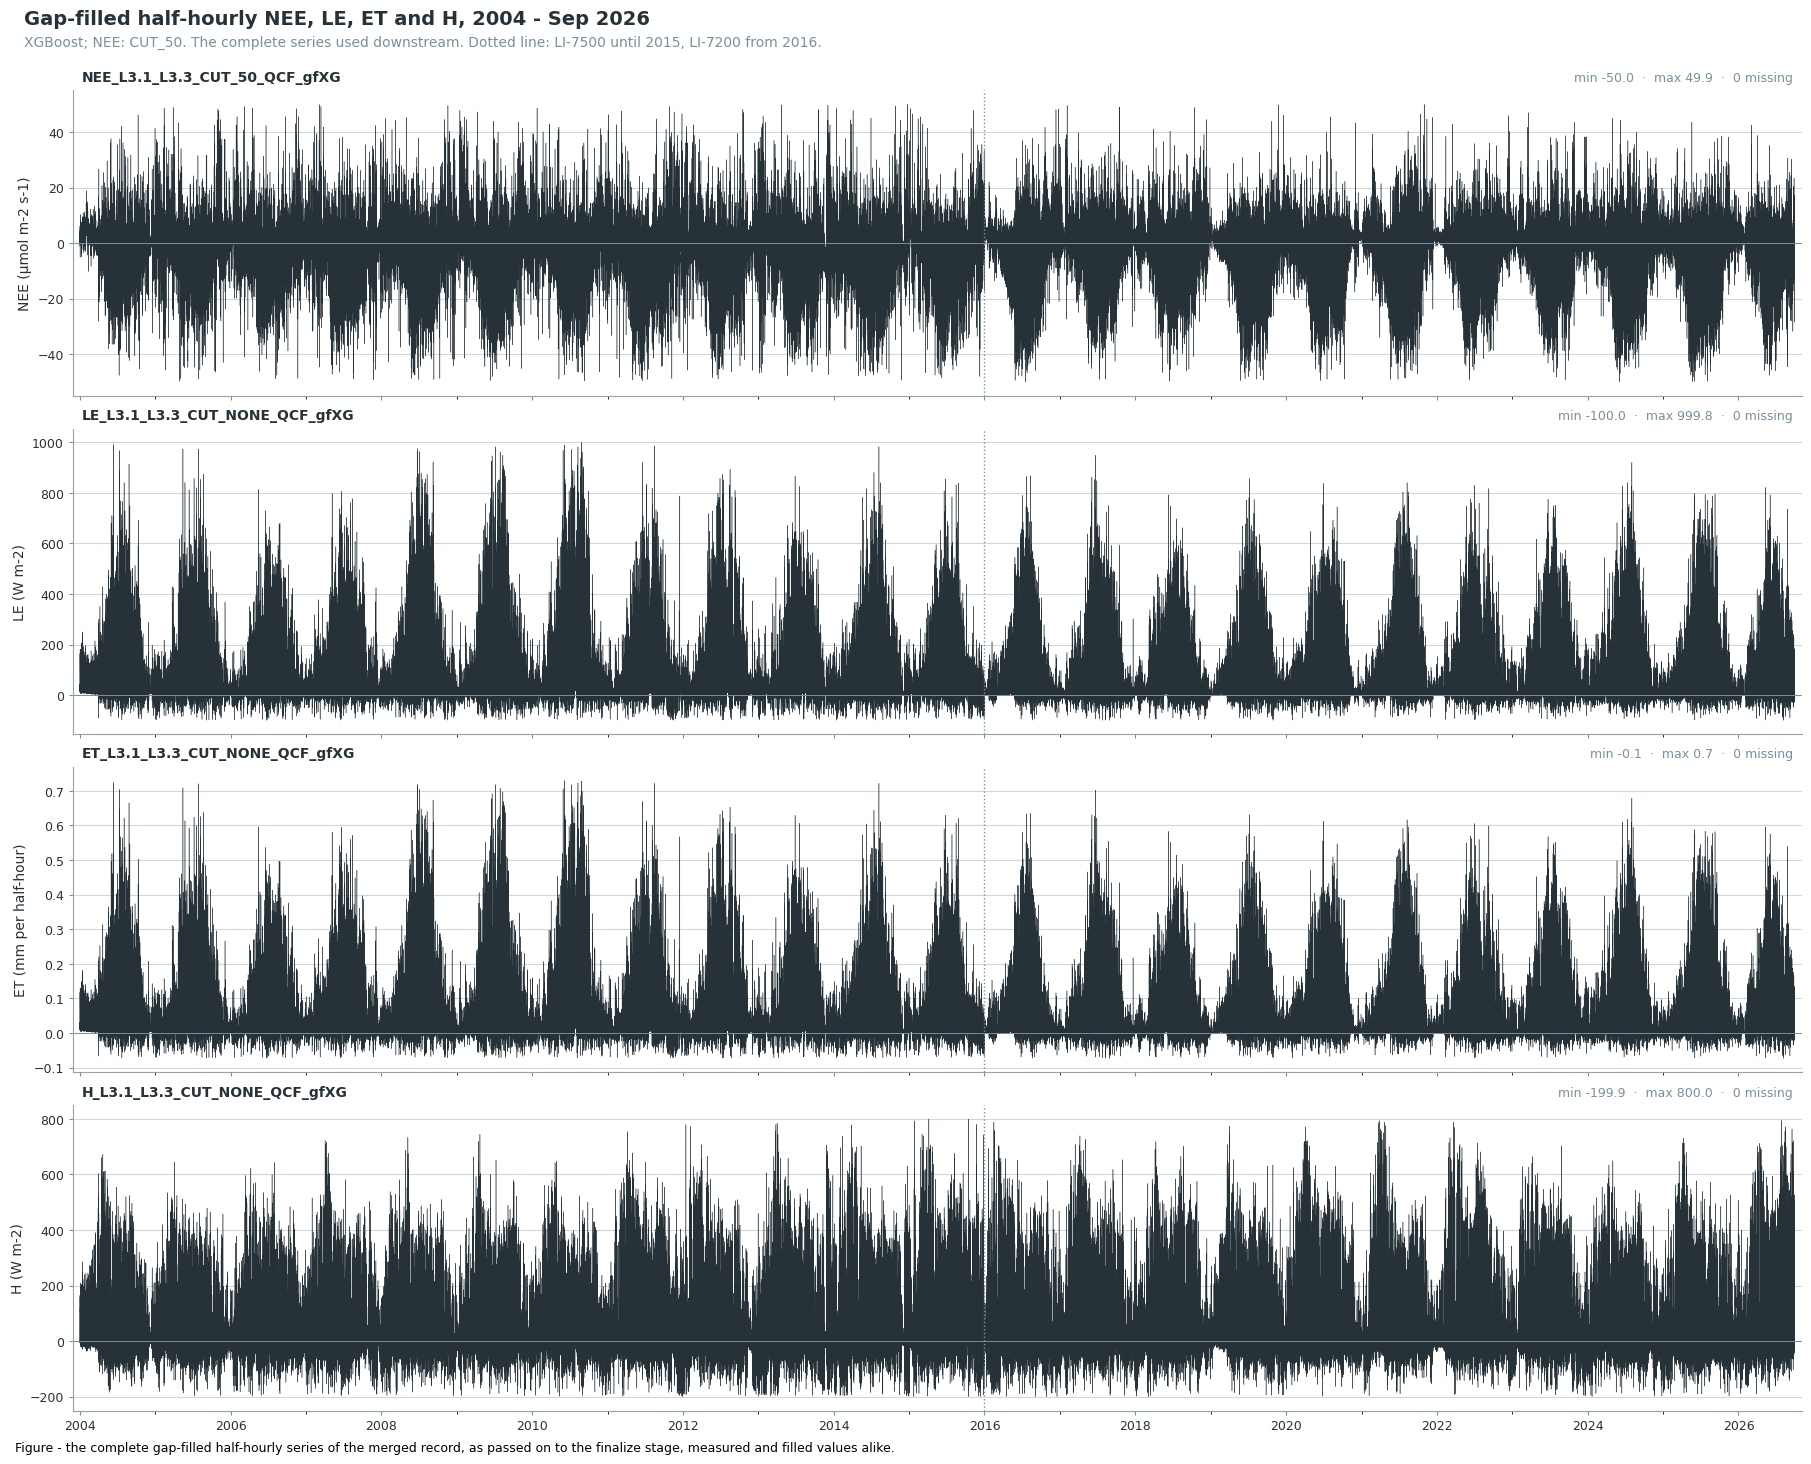

In [10]:
# The complete gap-filled half-hourly series as they go into the finalize stage, one colour, no
# marking of measured or filled values: what a user of the dataset gets.
import matplotlib.dates as mdates

GAPFILLED = {'NEE (µmol m-2 s-1)': 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG',
             'LE (W m-2)': 'LE_L3.1_L3.3_CUT_NONE_QCF_gfXG',
             'ET (mm per half-hour)': 'ET_L3.1_L3.3_CUT_NONE_QCF_gfXG',
             'H (W m-2)': 'H_L3.1_L3.3_CUT_NONE_QCF_gfXG'}
fig, axs = plt.subplots(len(GAPFILLED), 1, figsize=(18, 3.4 * len(GAPFILLED) + 1), sharex=True,
                        layout='constrained')
for ax, (label, col) in zip(axs, GAPFILLED.items()):
    _s = merged[col]
    ax.plot(_s.index, _s.to_numpy(), color=cp.INK, linewidth=0.3, rasterized=True)
    ax.axhline(0, color=cp.MUTED, linewidth=0.7)
    ax.axvline(_switch, color=cp.MUTED, linewidth=1, linestyle=':')
    ax.set_ylabel(label)
    ax.margins(x=0.004)
    cp.style_axes(ax)
    cp.panel_label(ax, col)
    ax.text(0.995, 1.02, f"min {_s.min():.1f}  ·  max {_s.max():.1f}  ·  {_s.isna().sum()} missing",
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9, color=cp.MUTED)
axs[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axs[-1].xaxis.set_minor_locator(mdates.YearLocator(1))
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
cp.figure_title(fig, 'Gap-filled half-hourly NEE, LE, ET and H, 2004 - Sep 2026',
                'XGBoost; NEE: CUT_50. The complete series used downstream. Dotted line: LI-7500 until '
                '2015, LI-7200 from 2016.')
figcap(fig, "the complete gap-filled half-hourly series of the merged record, as passed on to the "
            "finalize stage, measured and filled values alike.")
plt.show()

### 📊 Plot: half-hourly values of the main fluxes, with candidate outliers

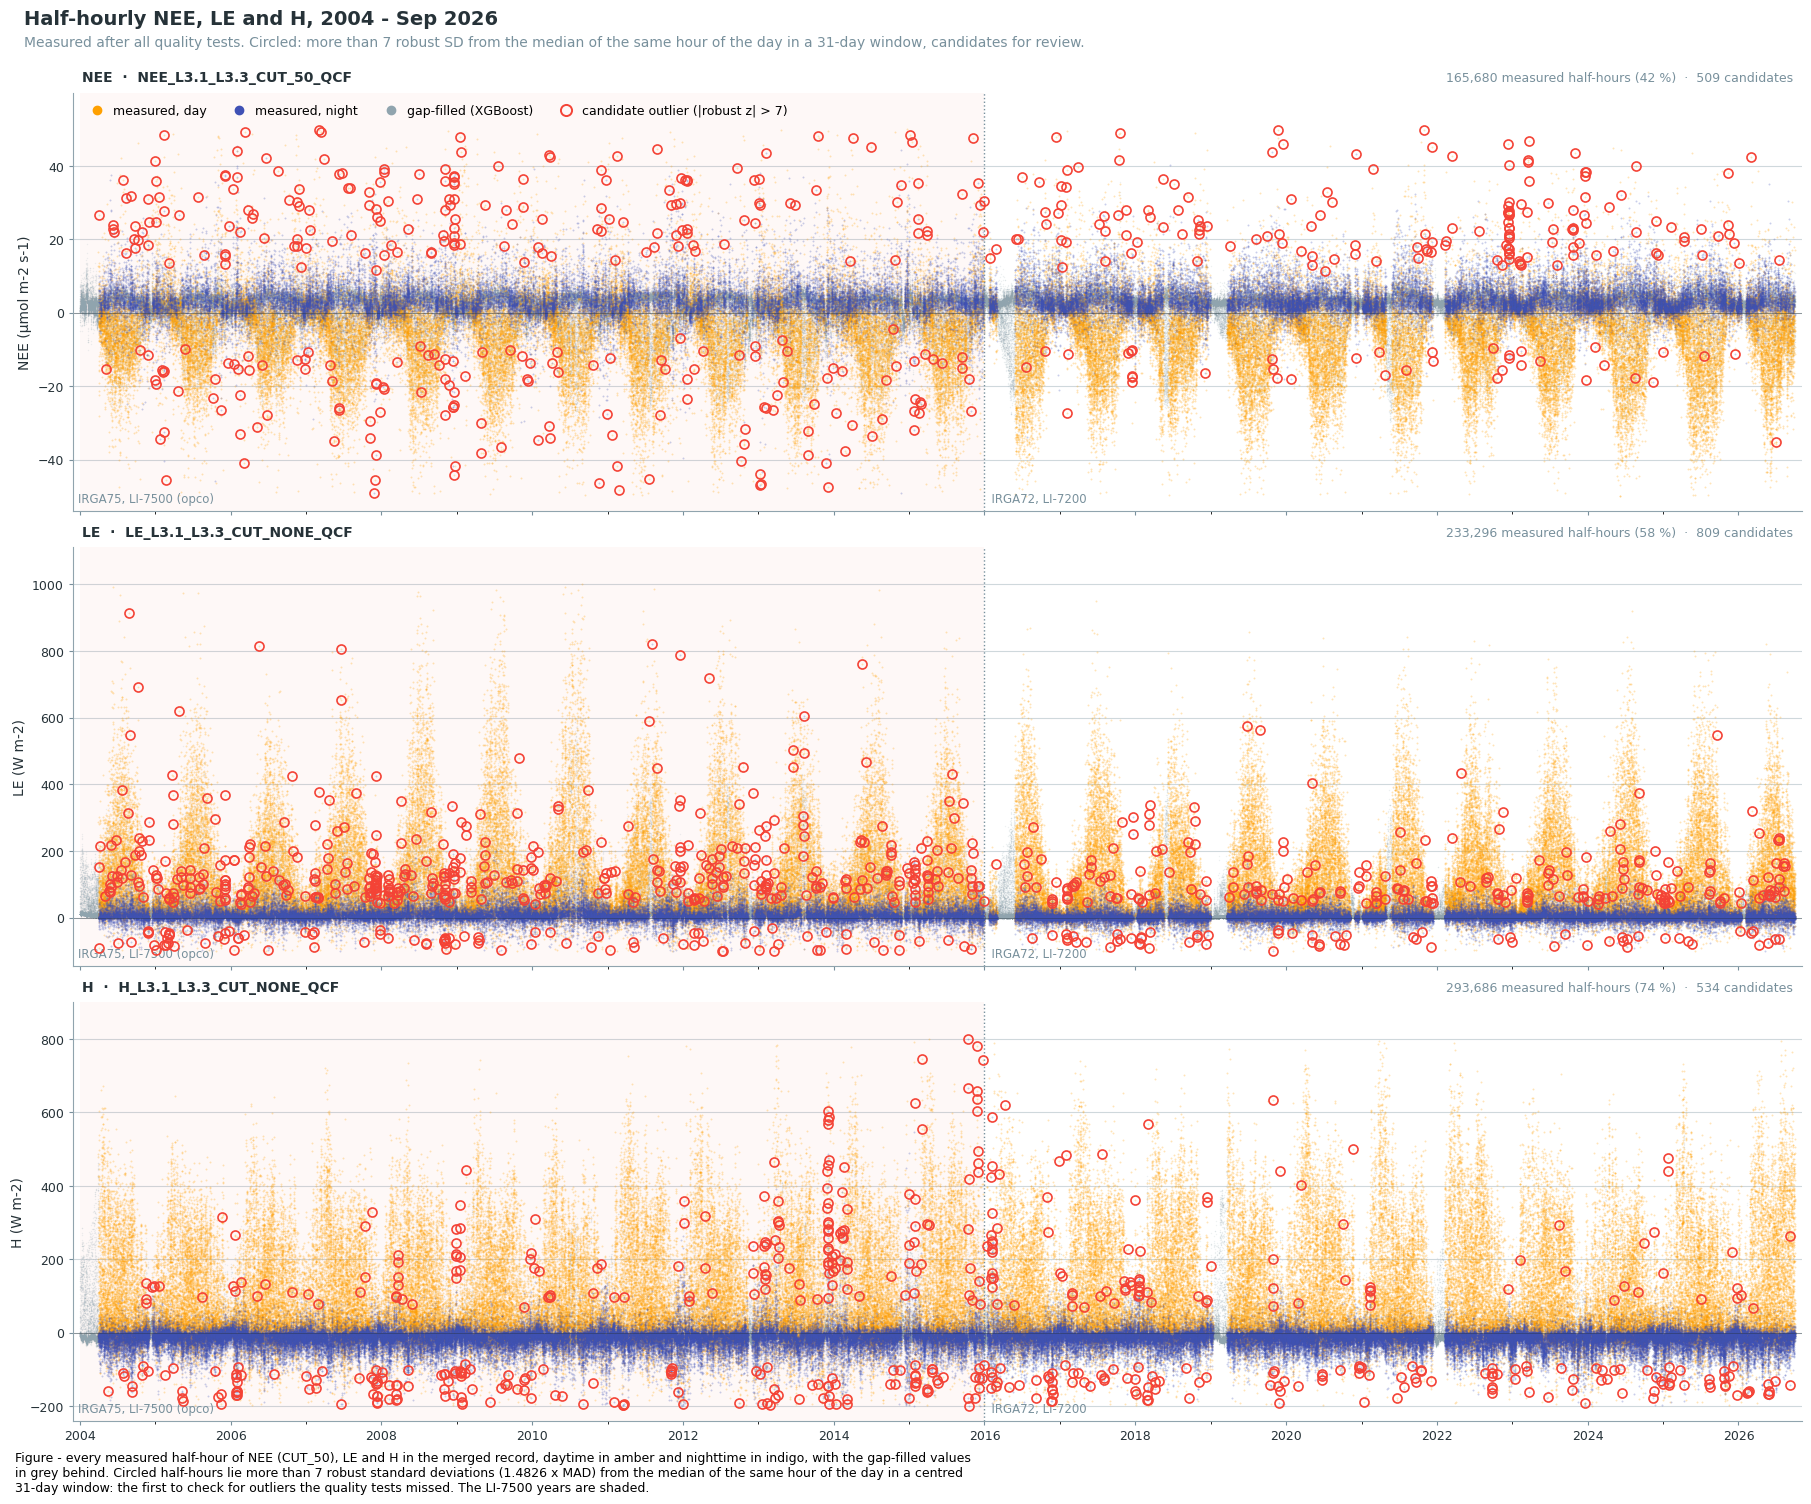

In [11]:
# Every measured half-hour of the three main fluxes after all quality tests (NEE: CUT_50), to find
# outliers the tests missed. Each half-hour is compared with the same hour of the day in a centred
# 31-day window: outside the median +/- OUTLIER_K robust standard deviations (1.4826 x MAD) it is
# circled as a candidate for review. The reference follows the daily cycle, so a normal noon value
# is not flagged for being far from the night. Nothing is removed here.
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

OUTLIER_K = 7
BAND_WINDOW = '31D'
HALFHOURLY = {'NEE': ('NEE_L3.1_L3.3_CUT_50_QCF', 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG', 'µmol m-2 s-1'),
              'LE': ('LE_L3.1_L3.3_CUT_NONE_QCF', 'LE_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'W m-2'),
              'H': ('H_L3.1_L3.3_CUT_NONE_QCF', 'H_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'W m-2')}


def robust_deviation(s, window=BAND_WINDOW):
    """Deviation of each value of `s` from the running median of the same hour of the day, in
    robust standard deviations. A spread of zero is raised to the 5th percentile of all spreads."""
    s = s.dropna()
    parts = []
    for _, g in s.groupby(s.index.hour):
        med = g.rolling(window, center=True, min_periods=10).median()
        sd = (g - med).abs().rolling(window, center=True, min_periods=10).median() * 1.4826
        parts.append(pd.DataFrame({'value': g, 'median': med, 'sd': sd}))
    out = pd.concat(parts).sort_index()
    out['sd'] = out['sd'].clip(lower=out['sd'].quantile(0.05))
    out['robust z'] = (out['value'] - out['median']) / out['sd']
    return out


CANDIDATES = {}
_is_day = merged['DAYTIME'].eq(1)
_pts = {**cp.POINTS, 'markersize': 1.4}
fig, axs = plt.subplots(len(HALFHOURLY), 1, figsize=(18, 4.6 * len(HALFHOURLY) + 1.2), sharex=True,
                        layout='constrained')
for ax, (name, (col, col_gf, unit)) in zip(axs, HALFHOURLY.items()):
    _measured = merged[col]
    _filled = merged[col_gf].where(_measured.isna())
    _dev = robust_deviation(_measured)
    _cand = _dev[_dev['robust z'].abs() > OUTLIER_K].copy()
    _cand['part of day'] = np.where(_is_day.reindex(_cand.index), 'day', 'night')
    CANDIDATES[name] = _cand
    ax.axvspan(pd.Timestamp(PERIODS['IRGA75'][0]), _switch, color=cp.REJECTED, alpha=0.035, linewidth=0)
    ax.plot(_filled.index, _filled.to_numpy(), color=cp.KEPT, alpha=0.15, **{**_pts, 'markersize': 1.0})
    for mask, color in ((_is_day, cp.DAY), (~_is_day, cp.NIGHT)):
        _s = _measured.where(mask)
        ax.plot(_s.index, _s.to_numpy(), color=color, alpha=0.28, **_pts)
    ax.plot(_cand.index, _cand['value'].to_numpy(), linestyle='none', marker='o', markersize=6.5,
            markerfacecolor='none', markeredgecolor=cp.REJECTED, markeredgewidth=1.2, zorder=5)
    ax.axvline(_switch, color=cp.MUTED, linewidth=1, linestyle=':')
    ax.axhline(0, color=cp.INK, linewidth=0.7, alpha=0.4)
    _lo, _hi = float(_measured.min()), float(_measured.max())
    ax.set_ylim(_lo - 0.04 * (_hi - _lo), _hi + 0.10 * (_hi - _lo))
    ax.margins(x=0.004)
    ax.set_ylabel(f"{name} ({unit})")
    cp.style_axes(ax)
    cp.panel_label(ax, f"{name}  ·  {col}")
    ax.text(0.995, 1.02, f"{_measured.notna().sum():,} measured half-hours ({100 * _measured.notna().mean():.0f} %)"
                         f"  ·  {len(_cand):,} candidates", transform=ax.transAxes, ha='right', va='bottom',
            fontsize=9, color=cp.MUTED)
_handles = [Line2D([], [], color=cp.DAY, marker='o', linestyle='none', markersize=6, label='measured, day'),
            Line2D([], [], color=cp.NIGHT, marker='o', linestyle='none', markersize=6, label='measured, night'),
            Line2D([], [], color=cp.KEPT, marker='o', linestyle='none', markersize=6, label='gap-filled (XGBoost)'),
            Line2D([], [], color=cp.REJECTED, marker='o', linestyle='none', markersize=8, markerfacecolor='none',
                   markeredgewidth=1.4, label=f'candidate outlier (|robust z| > {OUTLIER_K})')]
axs[0].legend(handles=_handles, frameon=False, fontsize=9, loc='upper left', ncol=4, handletextpad=0.3,
              columnspacing=1.6)
for ax in axs:
    ax.text(0.003, 0.02, 'IRGA75, LI-7500 (opco)', transform=ax.transAxes, fontsize=8.5, color=cp.MUTED)
    ax.text(_switch, 0.02, '  IRGA72, LI-7200', transform=ax.get_xaxis_transform(), fontsize=8.5,
            color=cp.MUTED)
axs[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axs[-1].xaxis.set_minor_locator(mdates.YearLocator(1))
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
cp.figure_title(fig, 'Half-hourly NEE, LE and H, 2004 - Sep 2026',
                f"Measured after all quality tests. Circled: more than {OUTLIER_K} robust SD from the "
                f"median of the same hour of the day in a 31-day window, candidates for review.")
figcap(fig, f"every measured half-hour of NEE (CUT_50), LE and H in the merged record, daytime in amber "
            f"and nighttime in indigo, with the gap-filled values in grey behind. Circled half-hours lie "
            f"more than {OUTLIER_K} robust standard deviations (1.4826 x MAD) from the median of the same "
            f"hour of the day in a centred 31-day window: the first to check for outliers the quality "
            f"tests missed. The LI-7500 years are shaded.")
plt.show()

### 📋 Table: candidate outliers per year

In [12]:
_counts = pd.DataFrame({name: c.groupby([c.index.year, 'part of day']).size()
                        for name, c in CANDIDATES.items()}).fillna(0).astype(int)
_counts.index.names = ['year', 'part of day']
display(_counts.unstack('part of day').rename_axis(columns=['flux', 'part of day']))

flux        NEE        LE         H      
part of day day night day night day night
year                                     
2004         11    10  14    25   2    11
2005         10    18  25    35   9     3
2006         17    16  20    16   6    12
2007         16    17  18    39   6    18
2008          6    41  11    54  12    22
2009         13     8  16    18  15    15
2010          8    12  12    17   5     9
2011         12    13  11    20   0    14
2012         11    11  21    27   3     9
2013          8    17  12    33  17    46
2014          7     8  10    23   1    27
2015          7    20  15    29  18    35
2016          3     9   8     6  12    29
2017         17     9  13    22   8    23
2018          9     7  16    16   6    23
2019          4     7   9    15   3    10
2020          8     7  13    11   4    10
2021          5    11  16    15   4    12
2022         18    15   6    12   1     8
2023         21    12   7    15   4     9
2024          3    11  13    18   5    14
2025          6     6   5    21   8    14
2026          2     2  15    16   2    10

### 📋 Table: the most extreme candidate outliers

In [13]:
# The most extreme candidates of each flux, by their distance from the running median of the same
# hour of the day, in robust standard deviations. Timestamps are TIMESTAMP_MIDDLE.
N_TOP = 15
_rows = []
for name, c in CANDIDATES.items():
    _top = c.reindex(c['robust z'].abs().sort_values(ascending=False).index).head(N_TOP)
    for ts, r in _top.iterrows():
        _rows.append({'flux': name, 'TIMESTAMP_MIDDLE': ts, 'part of day': r['part of day'],
                      'value': r['value'], 'running median': r['median'], 'robust z': r['robust z'],
                      'analyser': 'IRGA75' if ts < _switch else 'IRGA72'})
TOP_CANDIDATES = pd.DataFrame(_rows).set_index(['flux', 'TIMESTAMP_MIDDLE'])
display(TOP_CANDIDATES.round(2))

part of day   value  running median  robust z  \
flux TIMESTAMP_MIDDLE                                                    
NEE  2007-12-27 06:15:00       night   35.68           -0.35     20.25   
     2008-11-04 06:45:00       night   35.89            3.34     19.21   
     2005-02-12 14:15:00         day   48.51            3.56     18.95   
     2005-12-04 07:15:00       night   37.33            0.47     17.77   
     2012-10-23 09:15:00         day  -35.62           -0.61    -17.68   
     2015-01-16 13:15:00         day   46.54            1.52     17.66   
     2008-12-14 20:45:00       night  -25.55            1.66    -17.43   
     2010-12-24 00:45:00       night   36.19            1.57     16.93   
     2008-12-13 05:45:00       night  -25.79            0.41    -16.79   
     2008-07-09 01:15:00       night  -21.65            4.27    -16.61   
     2015-01-22 22:45:00       night  -31.85            0.76    -15.62   
     2011-01-06 21:15:00       night   25.41            1.19     15.52   
     2013-11-25 04:45:00       night  -40.80            1.23    -15.14   
     2008-12-15 17:45:00       night   30.95            1.20     14.78   
     2014-06-30 04:45:00         day   45.04            2.57     14.69   
LE   2017-12-21 00:45:00       night  302.16           -2.73     42.66   
     2011-12-16 22:15:00       night  788.29           12.08     42.29   
     2013-01-31 20:15:00       night  244.41            8.34     41.36   
     2007-12-06 00:45:00       night  425.15            8.92     37.76   
     2008-12-08 20:15:00       night  335.11            5.57     35.16   
     2010-05-07 01:45:00       night  334.58           10.75     29.43   
     2012-12-14 20:15:00       night  176.03           12.08     29.09   
     2011-08-05 00:15:00       night  819.36            7.35     27.88   
     2004-04-05 05:45:00       night  153.54            3.12     26.69   
     2017-12-21 01:45:00       night  252.40           -1.63     26.59   
     2015-04-01 02:45:00       night  123.86            2.17     21.59   
     2012-04-22 02:15:00       night  157.94            4.06     20.90   
     2013-08-07 22:15:00       night  605.22           10.46     20.15   
     2008-10-31 01:15:00       night  125.46            3.22     20.10   
     2005-12-03 19:15:00       night  172.34            5.35     18.81   
H    2015-10-14 04:45:00       night  799.82           -7.32     56.13   
     2015-10-14 04:15:00       night  667.80           -7.32     46.95   
     2015-10-14 05:45:00       night  282.25          -16.42     25.82   
     2013-11-29 19:15:00       night  338.59           -6.21     20.34   
     2016-02-05 02:15:00       night  220.65          -13.53     20.24   
     2016-02-05 22:45:00       night  327.24          -11.84     17.84   
     2013-12-04 21:45:00       night  354.03           -6.48     17.81   
     2014-03-07 03:15:00       night  335.61           -9.21     17.58   
     2013-03-18 07:45:00         day  463.54           11.18     16.98   
     2015-11-24 08:45:00         day  604.73           12.79     16.17   
     2016-02-03 23:15:00       night  424.80          -11.20     15.52   
     2013-12-01 19:15:00       night  257.34           -9.06     15.42   
     2013-12-06 00:45:00       night  300.59           -8.13     15.03   
     2016-01-11 18:15:00       night  234.94           -6.36     14.95   
     2015-01-28 12:15:00         day  363.49           15.04     14.84   

                         analyser  
flux TIMESTAMP_MIDDLE              
NEE  2007-12-27 06:15:00   IRGA75  
     2008-11-04 06:45:00   IRGA75  
     2005-02-12 14:15:00   IRGA75  
     2005-12-04 07:15:00   IRGA75  
     2012-10-23 09:15:00   IRGA75  
     2015-01-16 13:15:00   IRGA75  
     2008-12-14 20:45:00   IRGA75  
     2010-12-24 00:45:00   IRGA75  
     2008-12-13 05:45:00   IRGA75  
     2008-07-09 01:15:00   IRGA75  
     2015-01-22 22:45:00   IRGA75  
     2011-01-06 21:15:00   IRGA75  
     2013-11-25 04:45:00   IRGA75  
     2

### 📊 Plot: heatmaps of the main fluxes, date against time of day

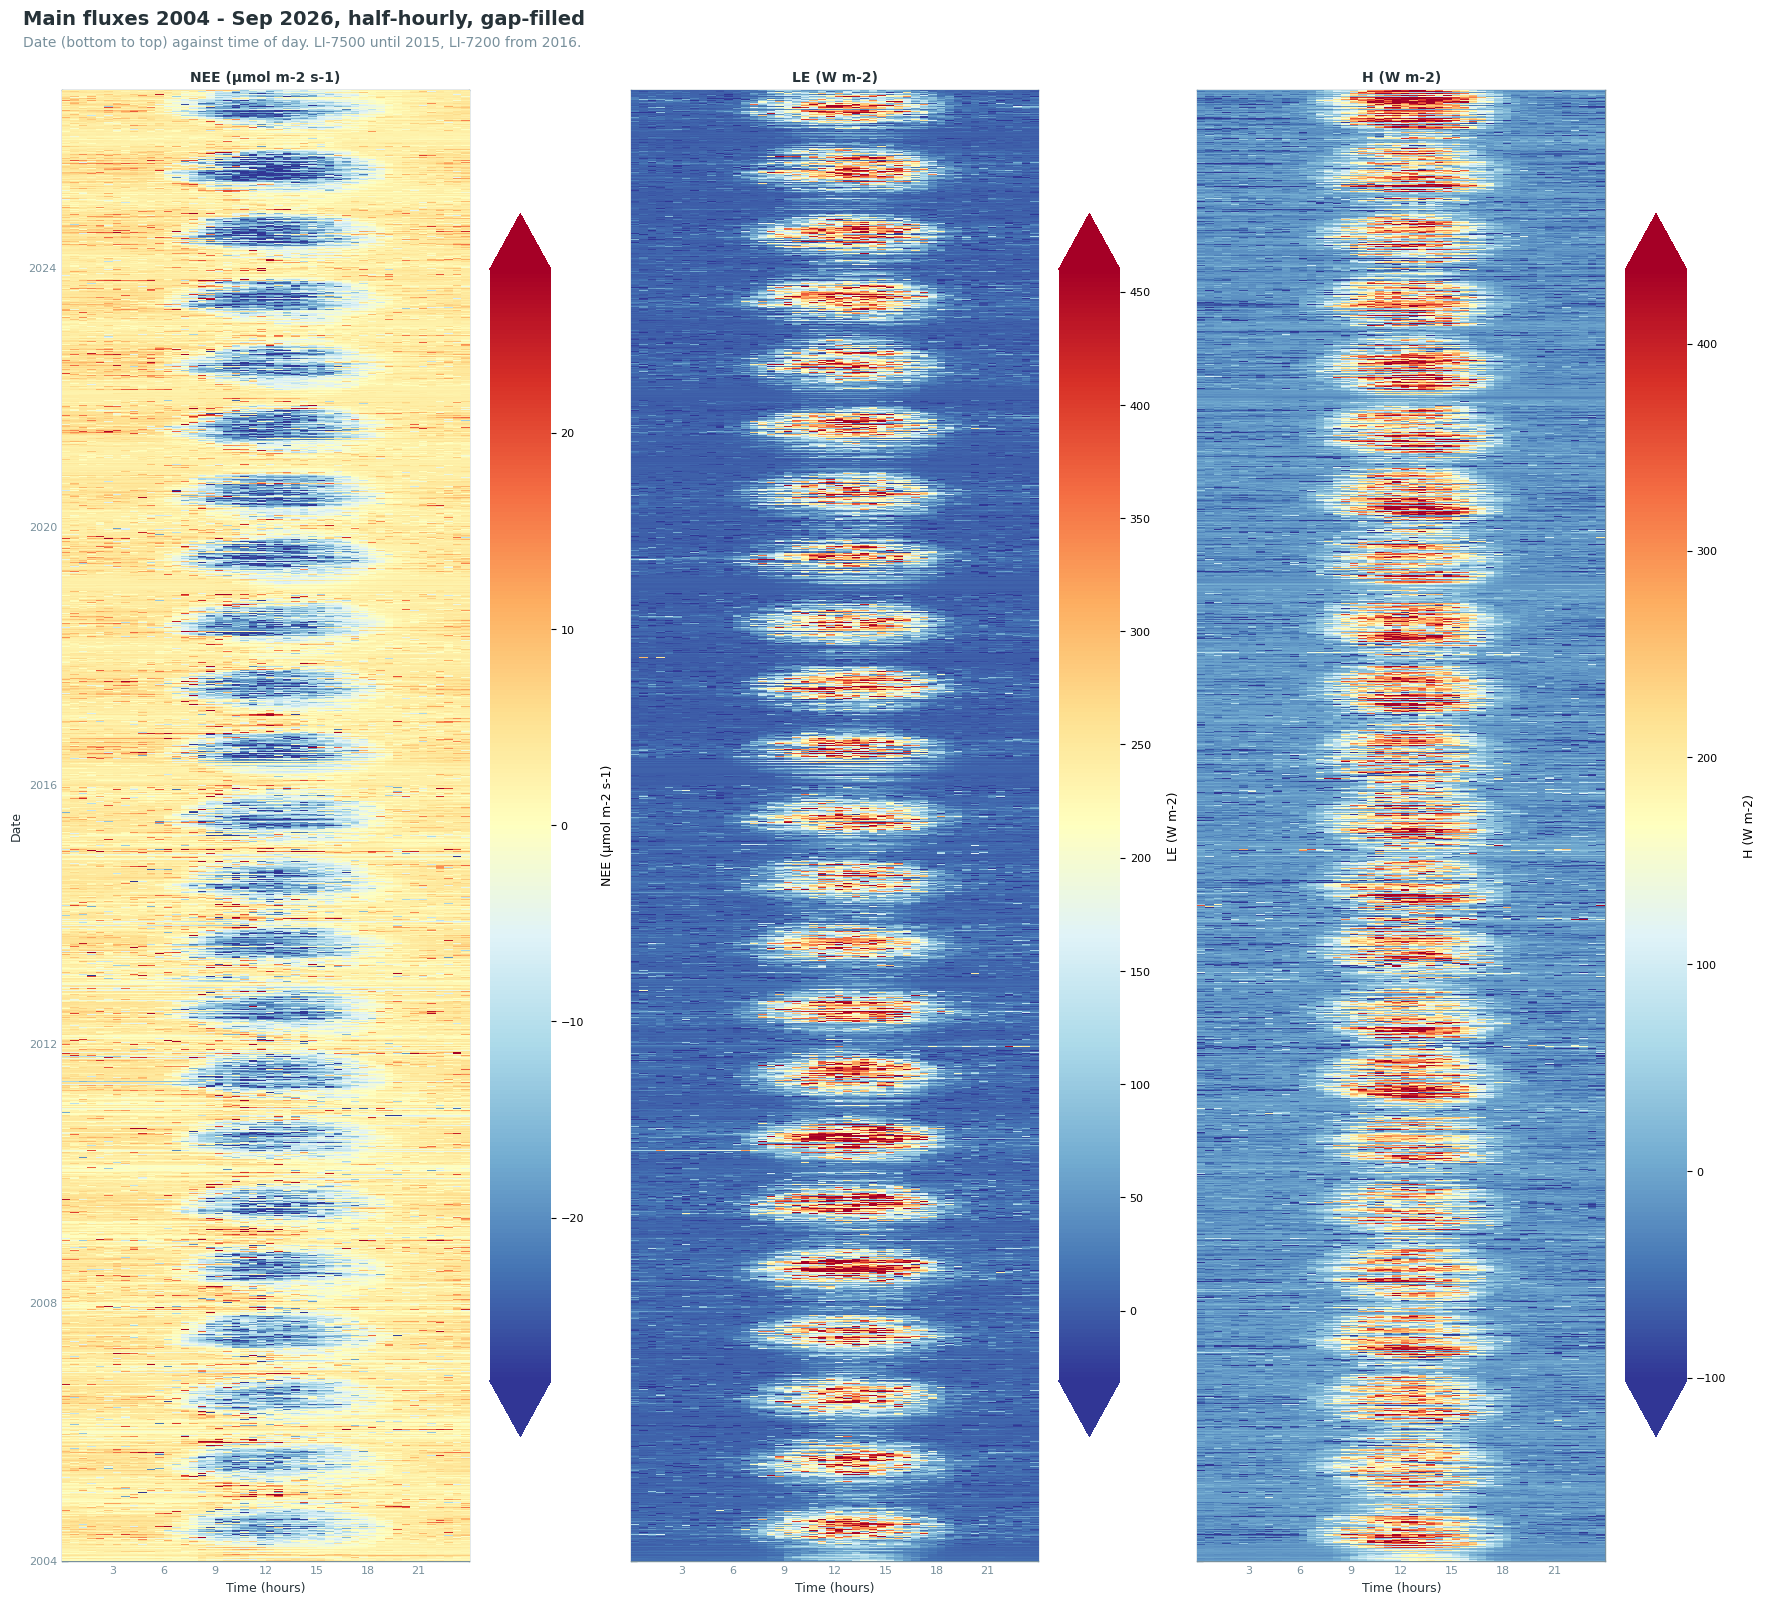

In [14]:
# One panel per flux, the gap-filled half-hourly values (XGBoost); colour scales at the 1st and 99th
# percentiles (NEE symmetric around zero).
_heat = {'NEE (µmol m-2 s-1)': SERIES['NEE'][0], 'LE (W m-2)': SERIES['LE'][0], 'H (W m-2)': SERIES['H'][0]}
fig, axs = plt.subplots(1, len(_heat), figsize=(17.6, 16), sharey=True, layout='constrained')
for _j, (ax, (title, col)) in enumerate(zip(axs, _heat.items())):
    _s = merged[col]
    _lo, _hi = (float(v) for v in _s.quantile([0.01, 0.99]))
    _lim = max(abs(_lo), abs(_hi)) if title.startswith('NEE') else None
    dv.plotting.HeatmapDateTime(series=_s, verbose=False).plot(
        ax=ax, fig=fig, vmin=-_lim if _lim else _lo, vmax=_lim if _lim else _hi, cmap=cp.HEATMAP_CMAP,
        cb_extend='both', cb_digits_after_comma='auto', cb_labelsize=8, zlabel=title,
        color_bad=cp.NAN_COLOR, as_image=True, format_style=cp.heatmap_style(title))
    if _j:
        plt.setp(ax.get_yticklabels(), visible=False)
        ax.yaxis.get_label().set_visible(False)
cp.figure_title(fig, 'Main fluxes 2004 - Sep 2026, half-hourly, gap-filled',
                'Date (bottom to top) against time of day. LI-7500 until 2015, LI-7200 from 2016.')
plt.show()

## 💾 Export

The merged file as parquet, and next to it an `_INFO.md` file that gives the source of each period and lists every column.

In [15]:
filepath = dv.save_parquet(data=merged, filename=OUTNAME, outpath=OUTPATH)
_lines = [f"# {OUTNAME}", "",
          f"{merged.index[0]} to {merged.index[-1]} ({merged.index.name}, UTC+01:00), "
          f"{merged.shape[0]:,} records x {merged.shape[1]} columns.",
          f"Written {datetime.now():%Y-%m-%d %H:%M} by `{OUTNAME}.ipynb`.", "",
          "| period | analyser | source file | `FLAG_FLUX_SOURCE` |", "|---|---|---|---|"]
_lines += [f"| {s} - {e} | {k} | `{FILES[k]}` | {SOURCE_CODES[k]} |" for k, (s, e) in PERIODS.items()]
_lines += ["", f"## Columns ({merged.shape[1]})", ""] + [f"- `{c}`" for c in merged.columns]
with open(rf"{OUTPATH}\{OUTNAME}_INFO.md", "w", encoding="utf-8") as _f:
    _f.write("\n".join(_lines) + "\n")
print(f"Saved to: {filepath}")
print(f"Wrote {OUTPATH}\\{OUTNAME}_INFO.md")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\99_FPPC_MERGED_2004-2026.09.parquet (1.753 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROCESSING_CHAIN\99_FPPC_MERGED_2004-2026.09.parquet
Wrote F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROCESSING_CHAIN\99_FPPC_MERGED_2004-2026.09_INFO.md


## ✅ Read the written file back

In [16]:
_written = dv.load_parquet(filepath=rf"{OUTPATH}\{OUTNAME}.parquet")
assert _written.index.equals(merged.index), "index changed on write"
assert list(_written.columns) == list(merged.columns), "columns changed on write"
for _c in MAIN + [SOURCE_COL]:
    assert _written[_c].equals(merged[_c]), f"{_c} changed on write"
print(f"Written file verified: {_written.shape[0]:,} records x {_written.shape[1]} columns")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\99_FPPC_MERGED_2004-2026.09.parquet (0.167 seconds).

Written file verified: 398,832 records x 205 columns


***

# End of notebook.

In [17]:
NOTEBOOK_END = datetime.now()
print(f"Runtime: {NOTEBOOK_END - NOTEBOOK_START}")

Runtime: 0:00:09.667995
